# Convertible de SPCX: valuación, árbol binomial, griegas y escenarios
Equipo 2 · Productos Derivados y Administración de Riesgos Corporativos (EGADE)

Este archivo corre completo como script (`python spcx_convertible.py`) y también como cuaderno de Colab:
cada bloque `# %%` es una celda. Todo el cálculo está aquí, sin depender del resto del repositorio.

**Idea central:** convertible = bono recto + opción call sobre la acción. Toda mejora del cupón o de la prima
de conversión tiene un precio en derivados.

**Estado de los supuestos.** Cada parámetro de la celda 1 dice si es dato de mercado, supuesto del caso Molson Coors
o supuesto del equipo. Nada está inventado en silencio.

In [1]:
# 0. Librerías (en Colab ya vienen instaladas; yfinance se instala con: !pip install -q yfinance)
from math import erf, exp, log, pi, sqrt

import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

logging.getLogger("yfinance").setLevel(logging.CRITICAL)   # menos ruido si no hay internet
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.figsize": (7.5, 3.8), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})
AZUL, ROJO, GRIS = "#14305c", "#a0222a", "#7a8396"

try:                                  # en Colab/Jupyter se ven como tablas; como script se imprimen
    from IPython.display import display as mostrar
except ImportError:
    mostrar = print

## 1. Parámetros y supuestos

In [2]:
PARAMS = {
    # nombre: (valor, fuente, estado)
    "S": (134.27, "TradingView/Yahoo, consulta del 8-nov-2026 (refleja el cierre del viernes 6)", "dato de mercado"),
    "prima": (0.32, "Prima de conversión elegida por el equipo", "supuesto del equipo"),
    "prima_warrant": (0.60, "Caso Molson Coors, Exhibit 1 (60 %)", "supuesto del caso"),
    "T": (6.0, "Plazo del caso Molson Coors", "supuesto del caso"),
    "r": (0.049, "UST a 6 años, aproximada (Refinitiv, 26-oct-2026)", "dato de mercado"),
    "sigma": (0.4893, "Volatilidad implícita de la opción call strike 130 que vence el 19-ene-2027 (TradingView, 8-nov)", "dato de mercado"),
    "ytm": (0.07195, "Yield de los bonos de SPCX a 6 años (Refinitiv, interpolado)", "calculado"),
    "nominal": (1000.0, "Valor nominal por bono", "supuesto del caso"),
    "emision_musd": (1000.0, "Monto de la emisión propuesta", "supuesto del equipo"),
    "acciones_circulacion_m": (13579.0, "Acciones en circulación (millones), Refinitiv", "dato de mercado"),
}
P = {k: v[0] for k, v in PARAMS.items()}
mostrar(pd.DataFrame([(k, *v) for k, v in PARAMS.items()], columns=["parámetro", "valor", "fuente", "estado"]).set_index("parámetro"))

,valor,fuente,estado
parámetro,,,
S,134.27000,"TradingView/Yahoo, consulta del 8-nov-2026 (re...",dato de mercado
prima,0.32000,Prima de conversión elegida por el equipo,supuesto del equipo
prima_warrant,0.60000,"Caso Molson Coors, Exhibit 1 (60 %)",supuesto del caso
T,6.00000,Plazo del caso Molson Coors,supuesto del caso
r,0.04900,"UST a 6 años, aproximada (Refinitiv, 26-oct-2026)",dato de mercado
sigma,0.48930,Volatilidad implícita de la opción call strike...,dato de mercado
ytm,0.07195,Yield de los bonos de SPCX a 6 años (Refinitiv...,calculado
nominal,1000.00000,Valor nominal por bono,supuesto del caso
emision_musd,1000.00000,Monto de la emisión propuesta,supuesto del equipo


## 2. Descarga de datos
Intenta bajar el historial de SPCX y de los comparables con `yfinance`. Si no hay internet (o el ticker no responde),
el script lo dice y sigue con la volatilidad implícita de la celda 1, sin inventar nada.

In [3]:
def descargar_precios(tickers=("SPCX", "BA", "SPY", "ITA"), inicio="2024-11-01"):
    """Cierres ajustados diarios. Devuelve un DataFrame o None si la descarga falla."""
    try:
        import yfinance as yf
        df = yf.download(list(tickers), start=inicio, auto_adjust=True, progress=False)["Close"]
        df = df.dropna(how="all")
        return df if len(df) > 20 else None
    except Exception as e:  # sin red, sin librería o ticker inexistente
        print("No se pudo descargar:", type(e).__name__)
        return None


precios = descargar_precios()
if precios is None:
    print("Sin datos descargados: se usa la volatilidad implícita de los parámetros (celda 1).")
else:
    print(precios.tail())

Sin datos descargados: se usa la volatilidad implícita de los parámetros (celda 1).


In [4]:
def vol_realizada(cierres: pd.Series, dias=252) -> float:
    r = np.log(cierres / cierres.shift(1)).dropna()
    return float(r.std(ddof=1) * sqrt(dias))


def vol_ewma(cierres: pd.Series, lam=0.94, dias=252) -> float:
    r = np.log(cierres / cierres.shift(1)).dropna().values
    var = r[:20].var(ddof=1)
    for x in r[20:]:
        var = lam * var + (1 - lam) * x * x
    return float(sqrt(var * dias))


if precios is not None and "SPCX" in precios:
    s = precios["SPCX"].dropna()
    print(f"SPCX: {len(s)} cierres desde {s.index[0].date()}")
    print(f"Volatilidad realizada total: {vol_realizada(s):.1%}")
    print(f"Volatilidad realizada últimos 60 días: {vol_realizada(s.tail(61)):.1%}")
    print(f"EWMA (λ = 0.94): {vol_ewma(s):.1%}")
    print(f"Implícita usada en la valuación: {P['sigma']:.1%}")
    s.plot(color=AZUL, title="SPCX: cierre diario (USD)")
    plt.show()
else:
    print(f"Volatilidad usada en la valuación (implícita): {P['sigma']:.2%}")

Volatilidad usada en la valuación (implícita): 48.93%


## 3. Black-Scholes, bono recto y convertible
Black-Scholes europeo sin dividendos. El bono recto se descuenta semestralmente con el yield de los bonos de SPCX.

In [5]:
def _cdf(x):
    return 0.5 * (1 + erf(x / sqrt(2)))


def _pdf(x):
    return exp(-0.5 * x * x) / sqrt(2 * pi)


def _d1d2(S, K, T, r, sg):
    d1 = (log(S / K) + (r + 0.5 * sg * sg) * T) / (sg * sqrt(T))
    return d1, d1 - sg * sqrt(T)


def bs_call(S, K, T, r, sg):
    d1, d2 = _d1d2(S, K, T, r, sg)
    return S * _cdf(d1) - K * exp(-r * T) * _cdf(d2)


def bs_put(S, K, T, r, sg):
    d1, d2 = _d1d2(S, K, T, r, sg)
    return K * exp(-r * T) * _cdf(-d2) - S * _cdf(-d1)


def valor_bono(cupon, ytm, T, nominal=1000.0, freq=2):
    n, i, pago = round(T * freq), ytm / freq, cupon * nominal / freq
    return sum(pago / (1 + i) ** k for k in range(1, n + 1)) + nominal / (1 + i) ** n


def cupon_equilibrio(objetivo, ytm, T, nominal=1000.0, freq=2):
    """El valor es lineal en el cupón, así que se resuelve de forma exacta."""
    base = valor_bono(0, ytm, T, nominal, freq)
    return (objetivo - base) / (valor_bono(1, ytm, T, nominal, freq) - base)


def convertible(S, prima, T, r, sg, ytm, nominal=1000.0):
    X = S * (1 + prima)
    acciones = nominal / X
    opcion = bs_call(S, X, T, r, sg) * acciones
    necesario = nominal - opcion
    return {"precio_conversion": X, "acciones_por_bono": acciones, "call_por_accion": bs_call(S, X, T, r, sg),
            "opcion_por_bono": opcion, "bono_recto_necesario": necesario,
            "cupon_equilibrio": cupon_equilibrio(necesario, ytm, T, nominal)}


base = convertible(P["S"], P["prima"], P["T"], P["r"], P["sigma"], P["ytm"], P["nominal"])
mostrar(pd.Series(base, name="valor").to_frame().round(4))

,valor
precio_conversion,177.2364
acciones_por_bono,5.6422
call_por_accion,61.1599
opcion_por_bono,345.0750
bono_recto_necesario,654.9250
cupon_equilibrio,0.0001


### Validación contra el caso Molson Coors (junio de 2007)
Con los supuestos del caso (precio 87.61, prima 25 %, tasa 4.46 %, volatilidad 23 %, 6 años, descuento 5.75 %)
el caso reporta una opción de 191.5 USD por bono y un cupón de equilibrio de 1.93 %.

In [6]:
mc = convertible(87.61, 0.25, 6, 0.0446, 0.23, 0.0575)
print(f"Opción por bono:     {mc['opcion_por_bono']:.2f}  (caso: 191.5)")
print(f"Bono recto necesario: {mc['bono_recto_necesario']:.2f}  (caso: 808.5)")
print(f"Cupón de equilibrio:  {mc['cupon_equilibrio']:.2%}  (caso: 1.93 %)")
assert abs(mc["opcion_por_bono"] - 191.5) < 0.1 and abs(mc["cupon_equilibrio"] - 0.0193) < 0.0001

Opción por bono:     191.52  (caso: 191.5)
Bono recto necesario: 808.48  (caso: 808.5)
Cupón de equilibrio:  1.93%  (caso: 1.93 %)


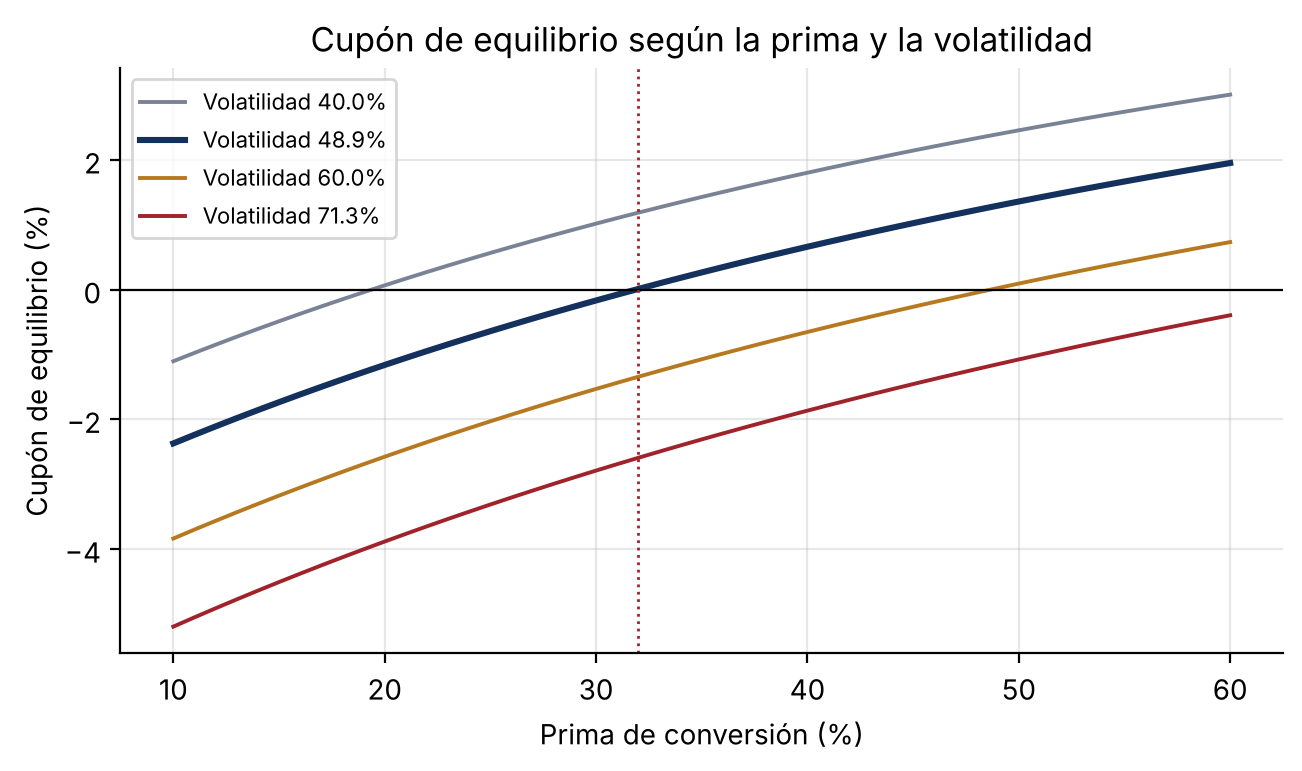

In [7]:
# Cupón de equilibrio según la prima y la volatilidad
primas = np.arange(0.10, 0.601, 0.01)
fig, ax = plt.subplots()
for sg, col, ls in [(0.40, GRIS, "-"), (P["sigma"], AZUL, "-"), (0.60, "#b7791f", "-"), (0.713, ROJO, "-")]:
    ax.plot(primas * 100, [convertible(P["S"], p, P["T"], P["r"], sg, P["ytm"])["cupon_equilibrio"] * 100 for p in primas],
            color=col, ls=ls, lw=2.2 if sg == P["sigma"] else 1.4, label=f"Volatilidad {sg:.1%}")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(P["prima"] * 100, color=ROJO, ls=":", lw=1)
ax.set(xlabel="Prima de conversión (%)", ylabel="Cupón de equilibrio (%)", title="Cupón de equilibrio según la prima y la volatilidad")
ax.legend(fontsize=8)
plt.show()

## 4. Árbol binomial (CRR)
Primero se verifica que el árbol europeo converge a Black-Scholes. Luego se valúa una put americana y se mide la prima
por ejercicio anticipado, que es lo que Black-Scholes no captura.

In [8]:
def crr(S, K, T, r, sg, N, tipo="call", americana=False, q=0.0):
    dt = T / N
    u = exp(sg * sqrt(dt))
    d = 1 / u
    p = (exp((r - q) * dt) - d) / (u - d)
    disc = exp(-r * dt)
    sgn = 1 if tipo == "call" else -1
    j = np.arange(N + 1)
    V = np.maximum(sgn * (S * u ** (N - j) * d ** j - K), 0.0)
    for i in range(N - 1, -1, -1):
        cont = disc * (p * V[: i + 1] + (1 - p) * V[1: i + 2])
        if americana:
            k = np.arange(i + 1)
            V = np.maximum(cont, np.maximum(sgn * (S * u ** (i - k) * d ** k - K), 0.0))
        else:
            V = cont
    return float(V[0])


X = base["precio_conversion"]
bs_ref = bs_call(P["S"], X, P["T"], P["r"], P["sigma"])
conv = pd.DataFrame({"N": (10, 50, 100, 500, 1000, 2000)})
conv["CRR europea"] = [crr(P["S"], X, P["T"], P["r"], P["sigma"], int(n)) for n in conv["N"]]
conv["Black-Scholes"] = bs_ref
conv["diferencia"] = conv["CRR europea"] - conv["Black-Scholes"]
print(f"Call strike {X:.2f}, vencimiento a {P['T']:.0f} años")
mostrar(conv.round(4).set_index("N"))

Call strike 177.24, vencimiento a 6 años


,CRR europea,Black-Scholes,diferencia
N,,,
10,62.0013,61.1599,0.8414
50,61.1463,61.1599,-0.0136
100,61.1373,61.1599,-0.0225
500,61.1785,61.1599,0.0186
1000,61.1672,61.1599,0.0074
2000,61.1595,61.1599,-0.0004


In [9]:
# Put americana de ejemplo: strike 160, 30 días, tasa 5.09 %, volatilidad implícita de la cadena del 21-oct (tarea de clase)
S0, K0, T0, r0, sg0 = 159.31, 160.0, 30 / 365, 0.0509, 0.5991
eu = crr(S0, K0, T0, r0, sg0, 500, "put", americana=False)
am = crr(S0, K0, T0, r0, sg0, 500, "put", americana=True)
print(f"Put europea (CRR 500):   {eu:.4f}   Black-Scholes: {bs_put(S0, K0, T0, r0, sg0):.4f}")
print(f"Put americana (CRR 500): {am:.4f}")
print(f"Prima por ejercicio anticipado: {am - eu:.4f} USD ({(am / eu - 1):.2%})")

Put europea (CRR 500):   10.9178   Black-Scholes: 10.9144
Put americana (CRR 500): 10.9623
Prima por ejercicio anticipado: 0.0445 USD (0.41%)


## 5. Griegas
Griegas de Black-Scholes para el call comprado (note hedge, strike de conversión) y el warrant vendido (strike con 60 % de prima),
y de la posición del emisor. Unidades: vega por punto de volatilidad, theta por día.

In [10]:
def griegas(S, K, T, r, sg, tipo="call"):
    d1, d2 = _d1d2(S, K, T, r, sg)
    gamma = _pdf(d1) / (S * sg * sqrt(T))
    vega = S * _pdf(d1) * sqrt(T) / 100
    decay = -S * _pdf(d1) * sg / (2 * sqrt(T))
    if tipo == "call":
        delta, theta = _cdf(d1), decay - r * K * exp(-r * T) * _cdf(d2)
    else:
        delta, theta = _cdf(d1) - 1, decay + r * K * exp(-r * T) * _cdf(-d2)
    return {"delta": delta, "gamma": gamma, "vega": vega, "theta_dia": theta / 365}


S, T, r, sg = P["S"], P["T"], P["r"], P["sigma"]
K1 = S * (1 + P["prima"])
K2 = S * (1 + P["prima_warrant"])
acc_m = P["emision_musd"] / P["nominal"] * P["nominal"] / K1      # millones de acciones subyacentes
g1, g2 = griegas(S, K1, T, r, sg), griegas(S, K2, T, r, sg)
tabla = pd.DataFrame({"Call K1 (conversión / note hedge)": g1, "Warrant K2": g2}).T
print(f"K1 = {K1:.2f}   K2 = {K2:.2f}   acciones subyacentes = {acc_m:.3f} M")
mostrar(tabla.round(5))

K1 = 177.24   K2 = 214.83   acciones subyacentes = 5.642 M


,delta,gamma,vega,theta_dia
Call K1 (conversión / note hedge),0.73004,0.00205,1.08740,-0.01710
Warrant K2,0.67452,0.00224,1.18445,-0.01813


In [11]:
# Posición del emisor: opción de conversión vendida (short call K1), note hedge comprado (long call K1) y warrants vendidos (short call K2)
def posicion(g_conv, g_hedge, g_warr, acc):
    return {k: acc * (-g_conv[k] + g_hedge[k] - g_warr[k]) for k in g_conv}


sin_cob = {k: -acc_m * v for k, v in g1.items()}
con_cob = posicion(g1, g1, g2, acc_m)
res = pd.DataFrame({"Sin cobertura": sin_cob, "Con call spread": con_cob})
res.index = ["Delta (M acciones)", "Gamma (M acc. por USD)", "Vega (M USD por punto)", "Theta (M USD por día)"]
print("Posición del emisor (millones). Con cobertura sólo queda la exposición del warrant vendido:")
mostrar(res.round(4))

Posición del emisor (millones). Con cobertura sólo queda la exposición del warrant vendido:


,Sin cobertura,Con call spread
Delta (M acciones),-4.1190,-3.8057
Gamma (M acc. por USD),-0.0116,-0.0126
Vega (M USD por punto),-6.1353,-6.6829
Theta (M USD por día),0.0965,0.1023


## 6. Escenarios al vencimiento
Qué pasa con el precio de la acción dentro de 6 años. Sin cobertura, la dilución empieza en el precio de conversión (K1).
Con el call spread, empieza hasta el strike del warrant (K2).

In [12]:
def escenario(ST, K1, K2, acc_m):
    exceso = max(ST - K1, 0) * acc_m                  # lo que el convertible paga por encima de la par (M USD)
    warr = max(ST - K2, 0) * acc_m                    # lo que el emisor debe por los warrants (M USD)
    hedge = max(ST - K1, 0) * acc_m                   # lo que recibe del note hedge (M USD)
    return {"valor por bono": max(P["nominal"], ST * P["nominal"] / K1),
            "costo sin cobertura (M USD)": exceso, "costo con cobertura (M USD)": exceso - hedge + warr,
            "acciones nuevas sin cobertura (M)": acc_m if ST > K1 else 0.0,
            "acciones nuevas con cobertura (M)": acc_m * (1 - K2 / ST) if ST > K2 else 0.0}


precios_vto = [60, 100, 134.27, 177.24, 200, 214.83, 250, 300, 400]
esc = pd.DataFrame([escenario(s, K1, K2, acc_m) for s in precios_vto], index=pd.Index(precios_vto, name="Precio al vencimiento"))
mostrar(esc.round(2))

,valor por bono,costo sin cobertura (M USD),costo con cobertura (M USD),acciones nuevas sin cobertura (M),acciones nuevas con cobertura (M)
Precio al vencimiento,,,,,
60.00,1000.00,0.00,0.00,0.00,0.00
100.00,1000.00,0.00,0.00,0.00,0.00
134.27,1000.00,0.00,0.00,0.00,0.00
177.24,1000.02,0.02,0.00,5.64,0.00
200.00,1128.44,128.44,0.00,5.64,0.00
214.83,1212.11,212.11,0.00,5.64,0.00
250.00,1410.55,410.55,198.42,5.64,0.79
300.00,1692.65,692.65,480.53,5.64,1.60
400.00,2256.87,1256.87,1044.75,5.64,2.61


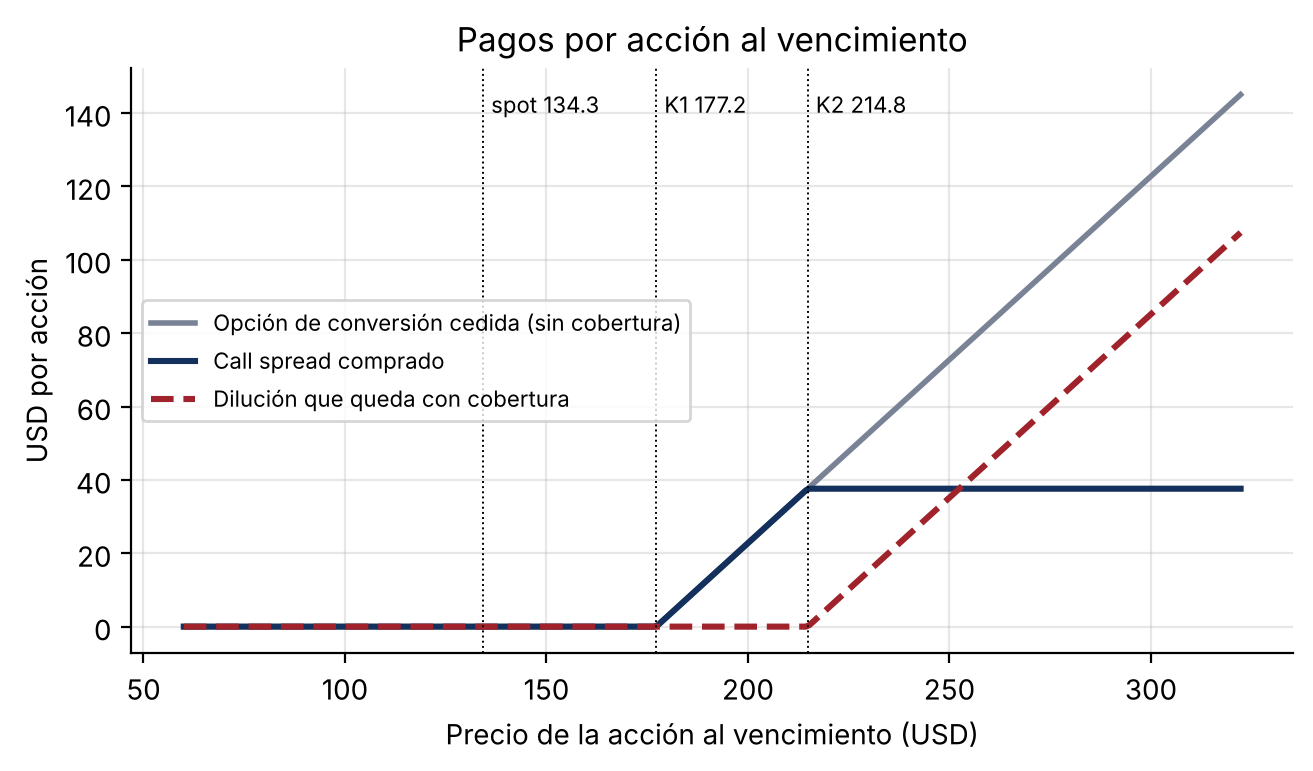

In [13]:
rango = np.linspace(60, 1.5 * K2, 300)
fig, ax = plt.subplots()
ax.plot(rango, [max(s - K1, 0) for s in rango], color=GRIS, lw=2, label="Opción de conversión cedida (sin cobertura)")
ax.plot(rango, [min(max(s - K1, 0), K2 - K1) for s in rango], color=AZUL, lw=2.2, label="Call spread comprado")
ax.plot(rango, [max(s - K1, 0) - min(max(s - K1, 0), K2 - K1) for s in rango], color=ROJO, lw=2.2, ls="--", label="Dilución que queda con cobertura")
for x, t in [(S, "spot"), (K1, "K1"), (K2, "K2")]:
    ax.axvline(x, color="black", lw=0.7, ls=":")
    ax.text(x + 2, ax.get_ylim()[1] * 0.92, f"{t} {x:.1f}", fontsize=8)
ax.set(xlabel="Precio de la acción al vencimiento (USD)", ylabel="USD por acción", title="Pagos por acción al vencimiento")
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(0.0, 0.5))
plt.show()

## 7. Costo del call spread
Costo neto = call comprado (K1) menos warrant vendido (K2), por las acciones subyacentes. Se paga una sola vez.

In [14]:
def costo_call_spread(S, K1, K2, T, r, sg, acc_m, sg_w=None):
    c1, c2 = bs_call(S, K1, T, r, sg), bs_call(S, K2, T, r, sg_w or sg)
    return {"call comprado (USD/acc.)": c1, "warrant vendido (USD/acc.)": c2, "costo call (M USD)": c1 * acc_m,
            "ingreso warrants (M USD)": c2 * acc_m, "costo neto (M USD)": (c1 - c2) * acc_m,
            "costo neto / emisión": (c1 - c2) * acc_m / P["emision_musd"],
            "dilución potencial / acciones en circulación": acc_m / P["acciones_circulacion_m"]}


filas = {f"vol {v:.1%}": costo_call_spread(S, K1, K2, T, r, v, acc_m) for v in (0.40, P["sigma"], 0.60, 0.713)}
mostrar(pd.DataFrame(filas).T.round(4))

,call comprado (USD/acc.),warrant vendido (USD/acc.),costo call (M USD),ingreso warrants (M USD),costo neto (M USD),costo neto / emisión,dilución potencial / acciones en circulación
vol 40.0%,51.1446,43.2118,288.5673,243.8087,44.7586,0.0448,0.0004
vol 48.9%,61.1599,54.0947,345.0750,305.2119,39.8631,0.0399,0.0004
vol 60.0%,72.6869,66.6750,410.1126,376.1926,33.9200,0.0339,0.0004
vol 71.3%,83.3273,78.3197,470.1480,441.8940,28.2540,0.0283,0.0004


## 8. Revisión
Los resultados de este archivo se compararon con el dashboard (`docs/index.html`) y con el reporte ejecutivo:
opción por bono de 345.1 USD, bono recto necesario de 654.9 USD, call spread neto de 39.9 M USD y 5.64 M de acciones
subyacentes. Los supuestos y su estado están en la celda 1.